First five rows of dataset:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset shape: (1728, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB
None

Missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


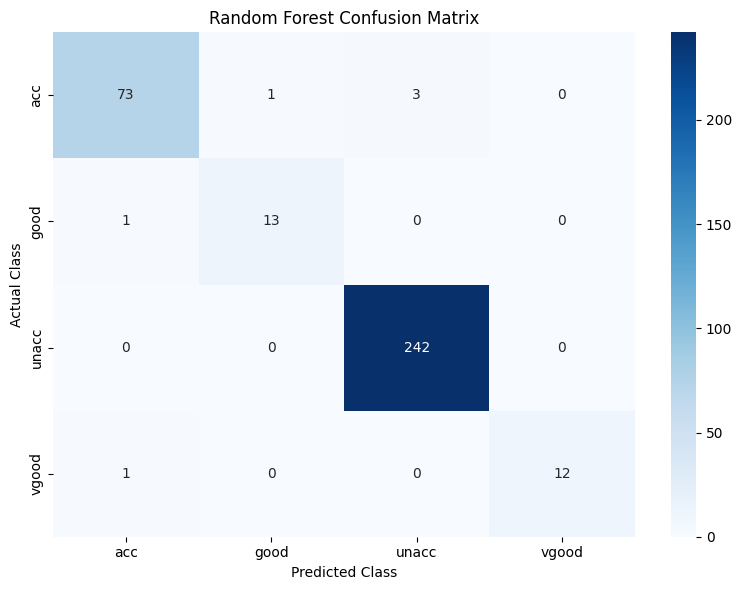


Feature Importance:
    Feature  Importance
5    safety    0.277857
3   persons    0.223212
0    buying    0.183894
1     maint    0.158944
4  lug_boot    0.086729
2     doors    0.069363


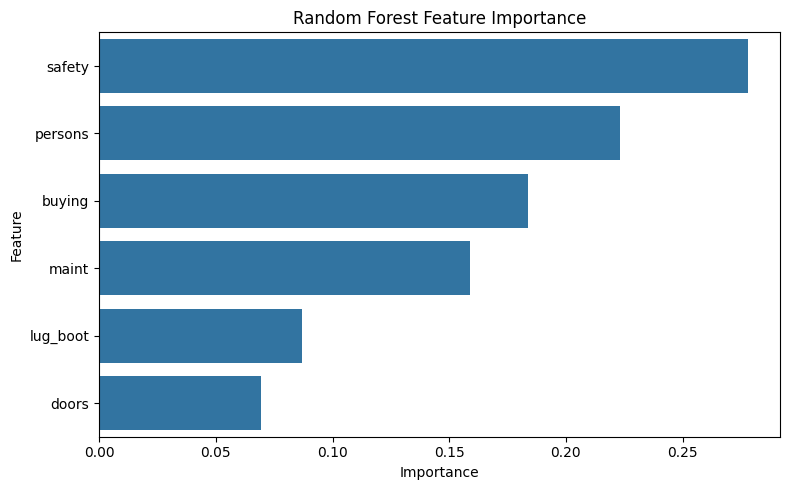


Predicted Car Safety:
unacc


In [3]:

# ==========================================================
# EXPERIMENT NO. 5: ENSEMBLE LEARNING USING RANDOM FOREST
# Aim: Predict car safety using Random Forest Classifier.
# ==========================================================


# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset splitting function
from sklearn.model_selection import train_test_split

# Import label encoder
from sklearn.preprocessing import LabelEncoder

# Import Random Forest algorithm
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# STEP 2: Download and load the Car Evaluation dataset

# Direct URL of the UCI Car Evaluation dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"

# Define column names because the dataset has no header
columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

# Read the dataset directly from the URL
df = pd.read_csv(url, names=columns)

# Display first five rows
print("First five rows of dataset:")
print(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display dataset information
print("\nDataset information:")
print(df.info())


# STEP 3: Check for missing values

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


# STEP 4: Separate input features and target

# X contains car features
X = df.drop("class", axis=1)

# y contains the car evaluation class
y = df["class"]

print("\nInput features:")
print(X.head())

print("\nTarget classes:")
print(y.unique())


# STEP 5: Convert categorical data into numerical data

# Random Forest requires numerical input.
# LabelEncoder converts text categories into numbers.

encoders = {}

for column in X.columns:

    # Create an encoder for each feature
    encoder = LabelEncoder()

    # Convert text values into numbers
    X[column] = encoder.fit_transform(X[column])

    # Store the encoder
    encoders[column] = encoder


# Encode target labels
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

print("\nEncoded input data:")
print(X.head())

print("\nEncoded target values:")
print(y[:10])


# STEP 6: Split dataset into training and testing data

# 80% data is used for training.
# 20% data is used for testing.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


# STEP 7: Create Random Forest Classifier

# n_estimators = 100 means 100 decision trees.
# random_state ensures reproducible results.

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


# STEP 8: Train the Random Forest model

# Train the model using training data
model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")


# STEP 9: Predict car safety

# Predict the classes for testing data
y_pred = model.predict(X_test)

print("\nPredicted values:")
print(y_pred[:10])

print("\nActual values:")
print(y_test[:10])


# STEP 10: Calculate model accuracy

# Compare predicted values with actual values
accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Model Accuracy:")
print(round(accuracy * 100, 2), "%")


# STEP 11: Display classification report

# Shows precision, recall, F1-score and support
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_encoder.classes_
    )
)


# STEP 12: Create confusion matrix

# Compare actual and predicted classes
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix using heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# STEP 13: Display feature importance

# Feature importance shows which car features
# contribute most to the model's predictions.

importance = model.feature_importances_

# Create DataFrame for feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance_df)

# Visualize feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


# STEP 14: Predict safety of a new car

# Example car:
# Buying price = vhigh
# Maintenance cost = high
# Doors = 4
# Persons = 4
# Luggage boot = big
# Safety = high

new_car = pd.DataFrame(
    [[
        "vhigh",
        "high",
        "4",
        "4",
        "big",
        "high"
    ]],
    columns=X.columns
)

# Convert new car values using the same encoders
for column in new_car.columns:

    new_car[column] = encoders[column].transform(
        new_car[column]
    )

# Predict the car evaluation class
prediction = model.predict(new_car)

# Convert numerical prediction back to text
predicted_class = target_encoder.inverse_transform(
    prediction
)

print("\nPredicted Car Safety:")
print(predicted_class[0])


# ==========================================================
# END OF EXPERIMENT NO. 5
# ==========================================================
